# 0. Quick Start: Configuration

Run this cell first after every kernel restart. It restores only lightweight,
project-wide constants and paths. It does not load images, restore the model,
run inference, or train anything.


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Locate the project without hard-coding a computer-specific drive or folder.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    path
    for path in [CURRENT_DIR, *CURRENT_DIR.parents]
    if (path / "notebooks").exists()
    and (path / "src").exists()
)

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
INTERIM_DATA_DIR = DATA_DIR / "interim"
CACHE_DATA_DIR = DATA_DIR / "cache_1000"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"
RESULTS_DIR = OUTPUTS_DIR / "results"

METADATA_PATH = INTERIM_DATA_DIR / "final_clean_metadata.csv"
BEST_MODEL_PATH = MODELS_DIR / "best_resnet18_high_res.pth"

# The order is fixed because it matches the six model output positions.
CLASS_NAMES = [
    "BIRD",
    "CAT",
    "EMPTY",
    "HEDGEHOG",
    "POSSUM",
    "RODENT",
]
CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}
ALERT_CLASSES = {
    "CAT",
    "HEDGEHOG",
    "POSSUM",
    "RODENT",
}

IMAGE_SIZE = 1000
INFERENCE_BATCH_SIZE = 2
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Device:", device)
print("Quick-start configuration complete.")


Project: E:\Code\ai-predator-early-warning
Device: cuda
Quick-start configuration complete.


# 1. Setup and Data Loading


Import the libraries and define the main project paths.

## 1.1 Imports and Paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = (
    INTERIM_DATA_DIR / "final_clean_metadata.csv"
)

## 1.2 Load Metadata

Load the cleaned dataset metadata created in the previous notebook.

In [3]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (16962, 12)


,sequence,image_sequence,file,label,site,date,camera,project_class,split,zip_path,found_in_zip,quality_status
0,77378,image2,1106150852100835S082.jpg,BIRD,835,6/11/2015 8:52,S08,BIRD,train,images/1106150852100835S082.jpg,False,keep
1,41636,image3,210916072714043as433.jpg,BIRD,043a,9/21/2016 7:27,s43,BIRD,train,images/210916072714043as433.jpg,False,keep
2,58458,image2,240916111910017as082.jpg,BIRD,017a,9/24/2016 11:19,s08,BIRD,train,images/240916111910017as082.jpg,False,keep
3,36044,image2,161016171542019b9705.jpg,BIRD,019b,10/16/2016 17:15,970,BIRD,train,images/161016171542019b9705.jpg,False,keep
4,38018,image2,021116133626027cs082.jpg,BIRD,027c,11/2/2016 13:36,s08,BIRD,train,images/021116133626027cs082.jpg,False,keep


In [4]:
pd.crosstab(
    df["project_class"],
    df["split"]
)

split,test,train,val
project_class,,,
BIRD,448,1869,419
CAT,450,1999,402
EMPTY,444,1904,418
HEDGEHOG,450,1953,396
POSSUM,450,2064,450
RODENT,450,2011,385


#### Class Balance After Cleaning

The final dataset has small differences in class size because low-quality images were removed.

The class distribution is still relatively balanced, so no additional resampling is applied.

## 1.3 Define Classes and Device

Define the six classes used in the classification model.

In [5]:
CLASS_NAMES = [
    "BIRD",
    "CAT",
    "EMPTY",
    "HEDGEHOG",
    "POSSUM",
    "RODENT"
]

CLASS_TO_INDEX = {
    cls: idx
    for idx, cls in enumerate(CLASS_NAMES)
}

CLASS_TO_INDEX

{'BIRD': 0, 'CAT': 1, 'EMPTY': 2, 'HEDGEHOG': 3, 'POSSUM': 4, 'RODENT': 5}


Use a GPU if one is available. Otherwise, use the CPU.

In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: not available; CPU will be used.")

Device: cuda
NVIDIA GeForce RTX 5060 Laptop GPU


# 2. Data Pipeline

## 2.1 Image Transforms


Define image transformations for training, validation, and testing.

Training images use light augmentation. Validation and test images only use resizing and normalization.

In [48]:
IMAGE_SIZE = 1000

train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 2.2 Dataset Class


Create a custom PyTorch dataset to load images and class labels from the metadata.

In [8]:
class CameraTrapDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.image_dir
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path).convert("RGB")

        label = CLASS_TO_INDEX[row["project_class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

## 2.3 Create Split DataFrames

Split the metadata into training, validation, and test sets.

In [9]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 11800
Validation: 2470
Test: 2692


## 2.4 Create Image Cache

In [54]:
CACHE_DATA_DIR = PROJECT_ROOT / "data" / "cache_1000"

CACHE_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

cache_resize = transforms.Resize(1000)

In [55]:
from tqdm.auto import tqdm

for _, row in tqdm(
    df.iterrows(),
    total=len(df)
):
    source_path = (
        PROCESSED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    target_path = (
        CACHE_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    # Skip images already cached
    if target_path.exists():
        continue

    target_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    with Image.open(source_path) as image:
        image = image.convert("RGB")

        # Resize the shorter side to 1000 pixels
        image = cache_resize(image)

        image.save(
            target_path,
            quality=90
        )

  0%|          | 0/16962 [00:00<?, ?it/s]

## 2.5 Use Cached Images

In [57]:
train_dataset = CameraTrapDataset(
    train_df,
    CACHE_DATA_DIR,
    transform=train_transform
)

val_dataset = CameraTrapDataset(
    val_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

test_dataset = CameraTrapDataset(
    test_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

## 2.6 Create Safe DataLoaders

In [66]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## 2.7 Check Cached Image

In [60]:
row = train_df.iloc[0]

test_path = (
    CACHE_DATA_DIR
    / row["split"]
    / row["project_class"]
    / row["file"]
)

print("Exists:", test_path.exists())

with Image.open(test_path) as image:
    print("Image size:", image.size)

Exists: True
Image size: (1333, 1000)


## 2.8 Test Loading Speed

In [61]:
import time

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i == 9:
        break

elapsed = time.time() - start

print(f"10 batches: {elapsed:.1f} seconds")

10 batches: 22.8 seconds


# 3. Baseline CNN

Create a simple CNN as a baseline model.

The baseline gives a simple reference before using a stronger pretrained model.

## 3.1 Model


In [72]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convert different image sizes to a fixed feature size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [68]:
baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = baseline_model(
    images.to(device)
)

print("Output:", outputs.shape)

Input: torch.Size([2, 3, 1000, 1333])
Output: torch.Size([2, 6])


In [73]:
NUM_CLASSES = len(CLASS_NAMES)

baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

baseline_model

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)

## 3.2 Loss and Optimizer

Use cross-entropy loss for multi-class classification. Cross-Entropy Loss measures how far the model's prediction deviates from the correct answer.

Use Adam to update the model weights. Adam is an optimizer. It adjusts the weights in the neural network based on the errors and gradients calculated by cross-entropy, enabling the model to make more accurate predictions in the next round:

In [74]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

## 3.3 Training and Validation Functions

Create functions for model training and validation.

In [75]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 3.4 Train the Model

Train the baseline CNN for five epochs and record the training and validation results.

In [76]:
import time

NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate_model(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

Epoch 1/5 | Train Loss: 1.5139 | Train Acc: 0.3155 | Val Loss: 1.4445 | Val Acc: 0.3198 | Time: 17.4 min
Epoch 2/5 | Train Loss: 1.3926 | Train Acc: 0.3908 | Val Loss: 1.3666 | Val Acc: 0.3599 | Time: 16.6 min
Epoch 3/5 | Train Loss: 1.3210 | Train Acc: 0.4510 | Val Loss: 1.4046 | Val Acc: 0.4146 | Time: 16.9 min
Epoch 4/5 | Train Loss: 1.2610 | Train Acc: 0.4814 | Val Loss: 1.5279 | Val Acc: 0.3830 | Time: 18.0 min
Epoch 5/5 | Train Loss: 1.2186 | Train Acc: 0.5039 | Val Loss: 1.5861 | Val Acc: 0.3429 | Time: 21.8 min


## 3.5 Baseline Result

The high-resolution baseline CNN reached its best validation accuracy of 41.46% at epoch 3.

Training accuracy continued to increase after epoch 3, while validation accuracy decreased and validation loss increased. This suggests overfitting.

The high-resolution input performed better than the earlier low-resolution baseline, but the simple CNN still had limited classification performance.

## 3.6 Plot Learning Curves

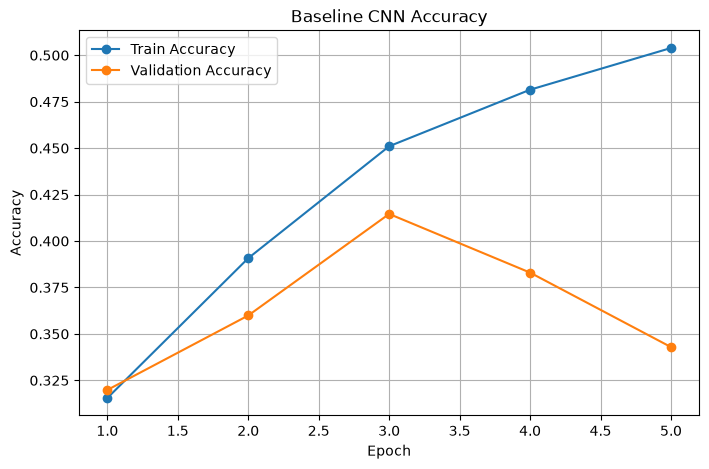

In [77]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()
plt.grid()

plt.show()

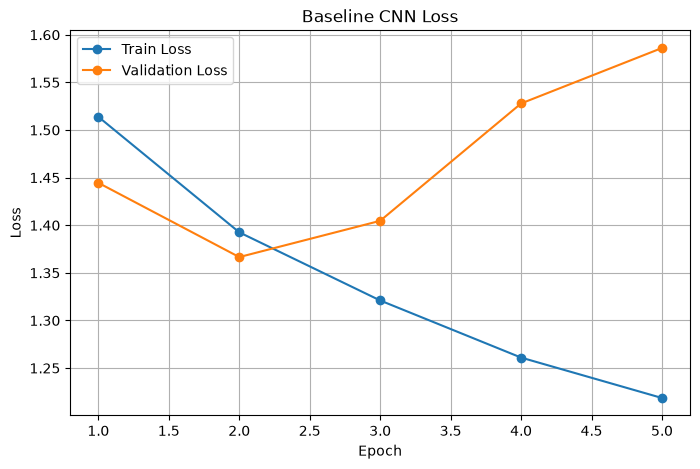

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()
plt.grid()

plt.show()

The baseline CNN showed clear overfitting after the first few epochs.

Training accuracy continued to increase, while validation accuracy peaked at 41.46% at epoch 3 and then decreased.

Validation loss also increased in later epochs, showing that the model did not generalize well to unseen images.

# 4. ResNet18

Use a pretrained ResNet18 model and fine-tune it for the six wildlife classes.

## 4.1 Load Pretrained Model

In [79]:
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

resnet_model = models.resnet18(
    weights=weights
)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

resnet_model = resnet_model.to(device)

## 4.2 Loss and Optimizer

Use cross-entropy loss and Adam for fine-tuning.

In [81]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    resnet_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda")

## 4.3 Training Functions

Use mixed precision to reduce GPU memory use and speed up training.

In [82]:
def train_one_epoch_amp(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model_amp(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type="cuda"
            ):
                outputs = model(images)
                loss = criterion(
                    outputs,
                    labels
                )

            total_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 4.4 Train ResNet18

Train ResNet18 for five epochs and save the best validation model.

In [83]:
import time

NUM_EPOCHS = 5

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

BEST_MODEL_PATH = (
    MODELS_DIR
    / "best_resnet18_high_res.pth"
)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch_amp(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device,
        scaler
    )

    val_loss, val_accuracy = evaluate_model_amp(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(
        train_loss
    )

    resnet_history["train_accuracy"].append(
        train_accuracy
    )

    resnet_history["val_loss"].append(
        val_loss
    )

    resnet_history["val_accuracy"].append(
        val_accuracy
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

print(
    "\nBest Val Acc:",
    round(best_val_accuracy, 4)
)

print(
    "Saved model:",
    BEST_MODEL_PATH
)

Epoch 1/5 | Train Loss: 1.1785 | Train Acc: 0.5257 | Val Loss: 1.5746 | Val Acc: 0.5356 | Time: 24.8 min
Epoch 2/5 | Train Loss: 0.8199 | Train Acc: 0.6878 | Val Loss: 0.9277 | Val Acc: 0.6818 | Time: 24.5 min
Epoch 3/5 | Train Loss: 0.6645 | Train Acc: 0.7582 | Val Loss: 1.0506 | Val Acc: 0.6842 | Time: 24.0 min
Epoch 4/5 | Train Loss: 0.6018 | Train Acc: 0.7810 | Val Loss: 0.9080 | Val Acc: 0.7126 | Time: 25.1 min
Epoch 5/5 | Train Loss: 0.5607 | Train Acc: 0.7964 | Val Loss: 0.8208 | Val Acc: 0.7134 | Time: 25.1 min

Best Val Acc: 0.7134
Saved model: e:\Code\ai-predator-early-warning\outputs\models\best_resnet18_high_res.pth


## 4.5 Continue Training

Continue training for three more epochs because validation performance is still improving.

In [84]:
TOTAL_EPOCHS = 8

for epoch in range(5, TOTAL_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch_amp(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device,
        scaler
    )

    val_loss, val_accuracy = evaluate_model_amp(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_accuracy"].append(train_accuracy)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{TOTAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

print(
    "\nBest Val Acc:",
    round(best_val_accuracy, 4)
)

Epoch 6/8 | Train Loss: 0.5192 | Train Acc: 0.8119 | Val Loss: 1.0522 | Val Acc: 0.6656 | Time: 23.0 min
Epoch 7/8 | Train Loss: 0.4860 | Train Acc: 0.8224 | Val Loss: 0.8367 | Val Acc: 0.7296 | Time: 23.3 min
Epoch 8/8 | Train Loss: 0.4583 | Train Acc: 0.8311 | Val Loss: 0.8418 | Val Acc: 0.6988 | Time: 24.8 min

Best Val Acc: 0.7296


## 4.6 Resume Inference Session

Restore the saved high-resolution ResNet18, validation/test metadata, and DataLoaders in one step after a kernel restart. This cell performs inference setup only and does not train the model.

In [13]:
# One-step recovery after a kernel restart
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image

PROJECT_ROOT = Path.cwd().parent.resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.inference_setup import (
    evaluate_model_amp,
    load_inference_session,
    run_inference,
)

resume_state = load_inference_session(
    project_root=PROJECT_ROOT,
    batch_size=2,
    num_workers=0,
)

# Restore the variable names used by the remaining notebook cells.
globals().update(resume_state)

print("Inference session restored.")
print("Device:", device)
print("Checkpoint:", BEST_MODEL_PATH)
print("Validation images:", len(val_df))
print("Test images:", len(test_df))


Inference session restored.
Device: cuda
Checkpoint: E:\Code\ai-predator-early-warning\outputs\models\best_resnet18_high_res.pth
Validation images: 2470
Test images: 2692


# 5. Validation-Only Alert Policy Selection

Select the alert-score method and threshold using validation data only. Configurations within 0.001 of the best validation F1 are treated as practically tied; among them, higher recall is preferred because missed alerts are more costly. The test set remains untouched until the policy is fixed.

## 5.1 Load Saved Validation Predictions

Read the validation predictions saved after model inference. This step performs
no training and no inference.


In [4]:
if "RESULTS_DIR" not in globals():
    raise RuntimeError(
        "Run Section 0: Quick Start Configuration first."
    )

VAL_PREDICTIONS_PATH = (
    RESULTS_DIR / "validation_predictions.csv"
)

if not VAL_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "Saved validation predictions were not found. "
        "Run Section 4.6 and validation inference once to create them."
    )

val_predictions_df = pd.read_csv(VAL_PREDICTIONS_PATH)

if len(val_predictions_df) != 2470:
    raise ValueError(
        "Saved validation predictions have an unexpected row count."
    )

print("Loaded saved validation predictions.")
print("Validation predictions:", len(val_predictions_df))
print("Path:", VAL_PREDICTIONS_PATH)

display(
    val_predictions_df[
        [
            "file",
            "true_class",
            "predicted_class",
            "true_alert",
            "sum_alert_score",
            "max_alert_score",
        ]
    ].head()
)


Loaded saved validation predictions.
Validation predictions: 2470
Path: E:\Code\ai-predator-early-warning\outputs\results\validation_predictions.csv


,file,true_class,predicted_class,true_alert,sum_alert_score,max_alert_score
0,130816131544023a6241.jpg,BIRD,BIRD,0,0.17870,0.128400
1,051116181530011b3102.jpg,BIRD,EMPTY,0,0.02045,0.014595
2,04121511491202201162.jpg,BIRD,BIRD,0,0.01270,0.012146
3,041116110014023a9232.jpg,BIRD,EMPTY,0,0.12890,0.079600
4,230816170024011bs103.jpg,BIRD,BIRD,0,0.15840,0.110530


## 5.2 Compare Sum and Max Alert Scores

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

THRESHOLDS = np.round(
    np.arange(0.10, 0.91, 0.05),
    2,
)

SCORE_METHODS = {
    "sum": "sum_alert_score",
    "max": "max_alert_score",
}


def evaluate_alert_thresholds(predictions_df, thresholds):
    rows = []
    y_true = predictions_df["true_alert"].to_numpy()

    for method, score_column in SCORE_METHODS.items():
        scores = predictions_df[score_column].to_numpy()

        for threshold in thresholds:
            y_pred = (scores >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1],
            ).ravel()

            rows.append(
                {
                    "method": method,
                    "score_column": score_column,
                    "threshold": float(threshold),
                    "accuracy": accuracy_score(y_true, y_pred),
                    "precision": precision_score(
                        y_true, y_pred, zero_division=0
                    ),
                    "recall": recall_score(
                        y_true, y_pred, zero_division=0
                    ),
                    "f1": f1_score(
                        y_true, y_pred, zero_division=0
                    ),
                    "f2": fbeta_score(
                        y_true, y_pred, beta=2, zero_division=0
                    ),
                    "true_negatives": int(tn),
                    "false_alerts": int(fp),
                    "missed_alerts": int(fn),
                    "true_positives": int(tp),
                }
            )

    return pd.DataFrame(rows)


validation_threshold_df = evaluate_alert_thresholds(
    val_predictions_df,
    THRESHOLDS,
)

# Pre-declared early-warning selection rule:
# treat F1 values within 0.001 of the best as practically tied, then prefer
# higher recall, higher precision, and finally the lower threshold.
MAX_VALIDATION_F1 = validation_threshold_df["f1"].max()
F1_TOLERANCE = 0.001

near_best_validation_df = validation_threshold_df[
    validation_threshold_df["f1"]
    >= MAX_VALIDATION_F1 - F1_TOLERANCE
].copy()

ranked_validation_df = near_best_validation_df.sort_values(
    by=["recall", "precision", "f1", "threshold"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

selected_validation_row = ranked_validation_df.iloc[0]
SELECTED_SCORE_METHOD = str(selected_validation_row["method"])
SELECTED_SCORE_COLUMN = str(selected_validation_row["score_column"])
SELECTED_THRESHOLD = float(selected_validation_row["threshold"])

best_by_method_df = (
    ranked_validation_df
    .drop_duplicates(subset="method", keep="first")
    .sort_values("method")
    .reset_index(drop=True)
)

val_predictions_df["selected_alert_score"] = (
    val_predictions_df[SELECTED_SCORE_COLUMN]
)
val_predictions_df["selected_threshold"] = SELECTED_THRESHOLD
val_predictions_df["predicted_alert"] = (
    val_predictions_df["selected_alert_score"] >= SELECTED_THRESHOLD
).astype(int)

selected_policy_df = pd.DataFrame(
    [
        {
            "selection_split": "validation",
            "selection_rule": (
                "within_0.001_of_best_f1_then_recall_then_precision_then_lower_threshold"
            ),
            "method": SELECTED_SCORE_METHOD,
            "score_column": SELECTED_SCORE_COLUMN,
            "threshold": SELECTED_THRESHOLD,
            "validation_accuracy": selected_validation_row["accuracy"],
            "validation_precision": selected_validation_row["precision"],
            "validation_recall": selected_validation_row["recall"],
            "validation_f1": selected_validation_row["f1"],
            "validation_f2": selected_validation_row["f2"],
            "validation_false_alerts": int(
                selected_validation_row["false_alerts"]
            ),
            "validation_missed_alerts": int(
                selected_validation_row["missed_alerts"]
            ),
        }
    ]
)

validation_threshold_df.to_csv(
    RESULTS_DIR / "validation_threshold_comparison.csv",
    index=False,
)
selected_policy_df.to_csv(
    RESULTS_DIR / "selected_alert_policy.csv",
    index=False,
)
val_predictions_df.to_csv(
    VAL_PREDICTIONS_PATH,
    index=False,
)

display(
    best_by_method_df[
        [
            "method",
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "f2",
            "false_alerts",
            "missed_alerts",
        ]
    ].round(4)
)

print("BEST VALIDATION F1:", f"{MAX_VALIDATION_F1:.6f}")
print("F1 NEAR-TIE TOLERANCE:", F1_TOLERANCE)
print("FIXED METHOD:", SELECTED_SCORE_METHOD)
print("FIXED SCORE COLUMN:", SELECTED_SCORE_COLUMN)
print("FIXED THRESHOLD:", f"{SELECTED_THRESHOLD:.2f}")


,method,threshold,accuracy,precision,recall,f1,f2,false_alerts,missed_alerts
0,max,0.35,0.9287,0.9344,0.9596,0.9468,0.9544,110,66
1,sum,0.45,0.9296,0.9309,0.9651,0.9477,0.9581,117,57


BEST VALIDATION F1: 0.947720
F1 NEAR-TIE TOLERANCE: 0.001
FIXED METHOD: sum
FIXED SCORE COLUMN: sum_alert_score
FIXED THRESHOLD: 0.45


## 5.3 Validation Threshold Trade-off

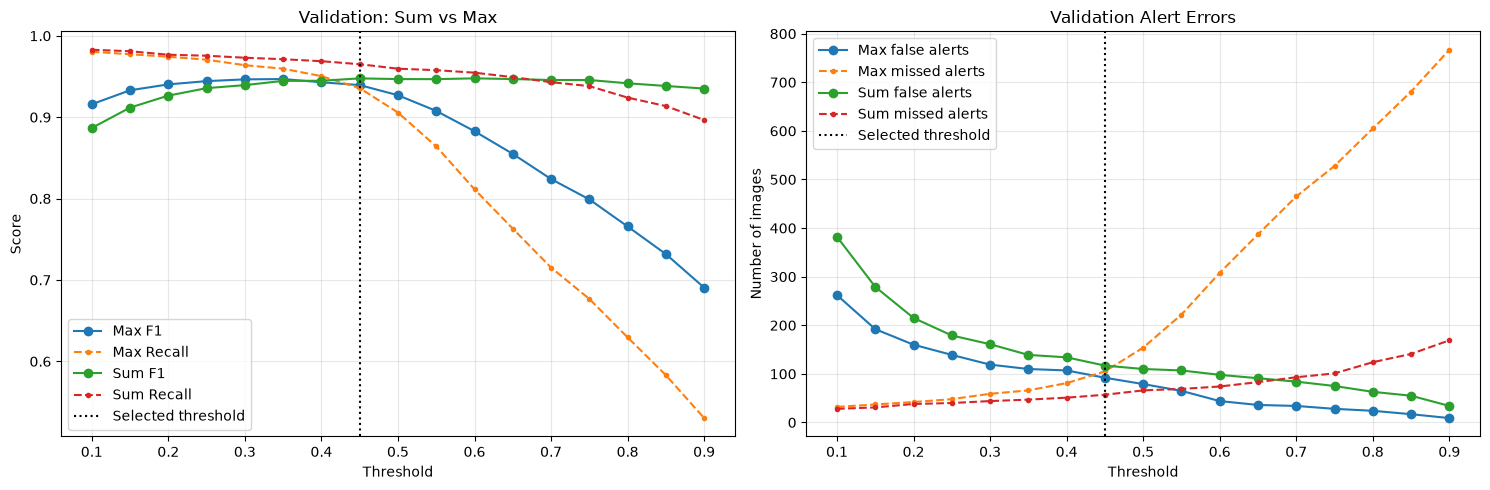

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for method, method_df in validation_threshold_df.groupby("method"):
    axes[0].plot(
        method_df["threshold"],
        method_df["f1"],
        marker="o",
        label=f"{method.title()} F1",
    )
    axes[0].plot(
        method_df["threshold"],
        method_df["recall"],
        marker=".",
        linestyle="--",
        label=f"{method.title()} Recall",
    )
    axes[1].plot(
        method_df["threshold"],
        method_df["false_alerts"],
        marker="o",
        label=f"{method.title()} false alerts",
    )
    axes[1].plot(
        method_df["threshold"],
        method_df["missed_alerts"],
        marker=".",
        linestyle="--",
        label=f"{method.title()} missed alerts",
    )

for axis in axes:
    axis.axvline(
        SELECTED_THRESHOLD,
        color="black",
        linestyle=":",
        label="Selected threshold",
    )
    axis.set_xlabel("Threshold")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_title("Validation: Sum vs Max")
axes[0].set_ylabel("Score")
axes[1].set_title("Validation Alert Errors")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "validation_sum_vs_max.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# 6. Fixed Final Test Evaluation

The alert method and threshold are now fixed. The test set is used once for
final performance estimation; no policy decision is changed after viewing the
following results.

## 6.1 Load Saved Final Test Predictions

Read the final test predictions saved after the fixed validation policy was
chosen. This step performs no training and no inference.


In [10]:
if "RESULTS_DIR" not in globals():
    raise RuntimeError(
        "Run Section 0: Quick Start Configuration first."
    )

TEST_PREDICTIONS_PATH = RESULTS_DIR / "test_predictions.csv"

if not TEST_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "Saved test predictions were not found. "
        "Run Section 4.6 and final test inference once to create them."
    )

test_predictions_df = pd.read_csv(TEST_PREDICTIONS_PATH)

if len(test_predictions_df) != 2692:
    raise ValueError(
        "Saved test predictions have an unexpected row count."
    )

print("Loaded saved test predictions.")
print("Test predictions:", len(test_predictions_df))
print("Path:", TEST_PREDICTIONS_PATH)


Loaded saved test predictions.
Test predictions: 2692
Path: E:\Code\ai-predator-early-warning\outputs\results\test_predictions.csv


## 6.2 Final Multiclass and Alert Metrics

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)

saved_class_index_table = (
    test_predictions_df[["true_class_index", "true_class"]]
    .drop_duplicates()
    .sort_values("true_class_index")
)
saved_class_names = saved_class_index_table["true_class"].tolist()

if saved_class_names != CLASS_NAMES:
    raise ValueError(
        "The saved prediction class order does not match CLASS_NAMES."
    )

if "SELECTED_THRESHOLD" not in globals():
    selected_policy_df = pd.read_csv(
        RESULTS_DIR / "selected_alert_policy.csv"
    )
    SELECTED_SCORE_METHOD = str(selected_policy_df.loc[0, "method"])
    SELECTED_SCORE_COLUMN = str(selected_policy_df.loc[0, "score_column"])
    SELECTED_THRESHOLD = float(selected_policy_df.loc[0, "threshold"])

test_predictions_df["selected_score_method"] = SELECTED_SCORE_METHOD
test_predictions_df["selected_alert_score"] = (
    test_predictions_df[SELECTED_SCORE_COLUMN]
)
test_predictions_df["selected_threshold"] = SELECTED_THRESHOLD
test_predictions_df["predicted_alert"] = (
    test_predictions_df["selected_alert_score"] >= SELECTED_THRESHOLD
).astype(int)

y_test_class = test_predictions_df["true_class_index"].to_numpy()
y_test_class_pred = (
    test_predictions_df["predicted_class_index"].to_numpy()
)
y_test_alert = test_predictions_df["true_alert"].to_numpy()
y_test_alert_pred = test_predictions_df["predicted_alert"].to_numpy()

test_classification_report_df = pd.DataFrame(
    classification_report(
        y_test_class,
        y_test_class_pred,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        digits=4,
        zero_division=0,
    )
).T

tn, fp, fn, tp = confusion_matrix(
    y_test_alert,
    y_test_alert_pred,
    labels=[0, 1],
).ravel()

test_multiclass_accuracy = accuracy_score(
    y_test_class,
    y_test_class_pred,
)

test_alert_metrics_df = pd.DataFrame(
    [
        {
            "method": SELECTED_SCORE_METHOD,
            "threshold": SELECTED_THRESHOLD,
            "accuracy": accuracy_score(y_test_alert, y_test_alert_pred),
            "precision": precision_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "recall": recall_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "f1": f1_score(
                y_test_alert, y_test_alert_pred, zero_division=0
            ),
            "f2": fbeta_score(
                y_test_alert,
                y_test_alert_pred,
                beta=2,
                zero_division=0,
            ),
            "true_negatives": int(tn),
            "false_alerts": int(fp),
            "missed_alerts": int(fn),
            "true_positives": int(tp),
        }
    ]
)

final_test_summary_df = pd.DataFrame(
    [
        {
            "multiclass_accuracy": test_multiclass_accuracy,
            "alert_method": SELECTED_SCORE_METHOD,
            "alert_threshold": SELECTED_THRESHOLD,
            "alert_accuracy": test_alert_metrics_df.loc[0, "accuracy"],
            "alert_precision": test_alert_metrics_df.loc[0, "precision"],
            "alert_recall": test_alert_metrics_df.loc[0, "recall"],
            "alert_f1": test_alert_metrics_df.loc[0, "f1"],
            "alert_f2": test_alert_metrics_df.loc[0, "f2"],
            "false_alerts": int(
                test_alert_metrics_df.loc[0, "false_alerts"]
            ),
            "missed_alerts": int(
                test_alert_metrics_df.loc[0, "missed_alerts"]
            ),
        }
    ]
)

test_predictions_df.to_csv(TEST_PREDICTIONS_PATH, index=False)
test_classification_report_df.to_csv(
    RESULTS_DIR / "final_test_classification_report.csv",
    index=True,
)
test_alert_metrics_df.to_csv(
    RESULTS_DIR / "final_test_alert_metrics.csv",
    index=False,
)
final_test_summary_df.to_csv(
    RESULTS_DIR / "final_test_summary.csv",
    index=False,
)

print("Fixed validation-selected policy")
print("Method:", SELECTED_SCORE_METHOD)
print("Threshold:", f"{SELECTED_THRESHOLD:.2f}")
print("Test multiclass accuracy:", f"{test_multiclass_accuracy:.4f}")
display(test_alert_metrics_df.round(4))
display(test_classification_report_df.round(4))


Fixed validation-selected policy
Method: sum
Threshold: 0.45
Test multiclass accuracy: 0.7047


,method,threshold,accuracy,precision,recall,f1,f2,true_negatives,false_alerts,missed_alerts,true_positives
0,sum,0.45,0.9261,0.9306,0.9611,0.9456,0.9549,763,129,70,1730


,precision,recall,f1-score,support
BIRD,0.9150,0.4085,0.5648,448.0000
CAT,0.8967,0.4822,0.6272,450.0000
EMPTY,0.5186,0.7860,0.6249,444.0000
HEDGEHOG,0.7491,0.8822,0.8102,450.0000
POSSUM,0.6558,0.8467,0.7391,450.0000
RODENT,0.7940,0.8222,0.8079,450.0000
accuracy,0.7047,0.7047,0.7047,0.7047
macro avg,0.7548,0.7046,0.6957,2692.0000
weighted avg,0.7553,0.7047,0.6959,2692.0000


## 6.3 Final Confusion Matrices

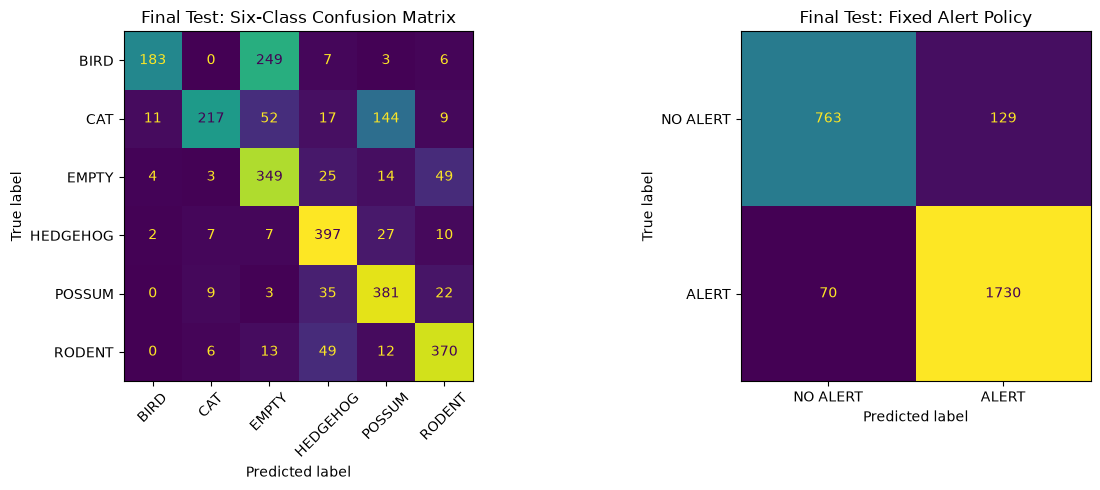

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    y_test_class_pred,
    labels=np.arange(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES,
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Final Test: Six-Class Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test_alert,
    y_test_alert_pred,
    labels=[0, 1],
    display_labels=["NO ALERT", "ALERT"],
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Final Test: Fixed Alert Policy")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# 7. Error Analysis and Explainability

## 7.1 Inspect False and Missed Alerts

False alerts: 129
Missed alerts: 70


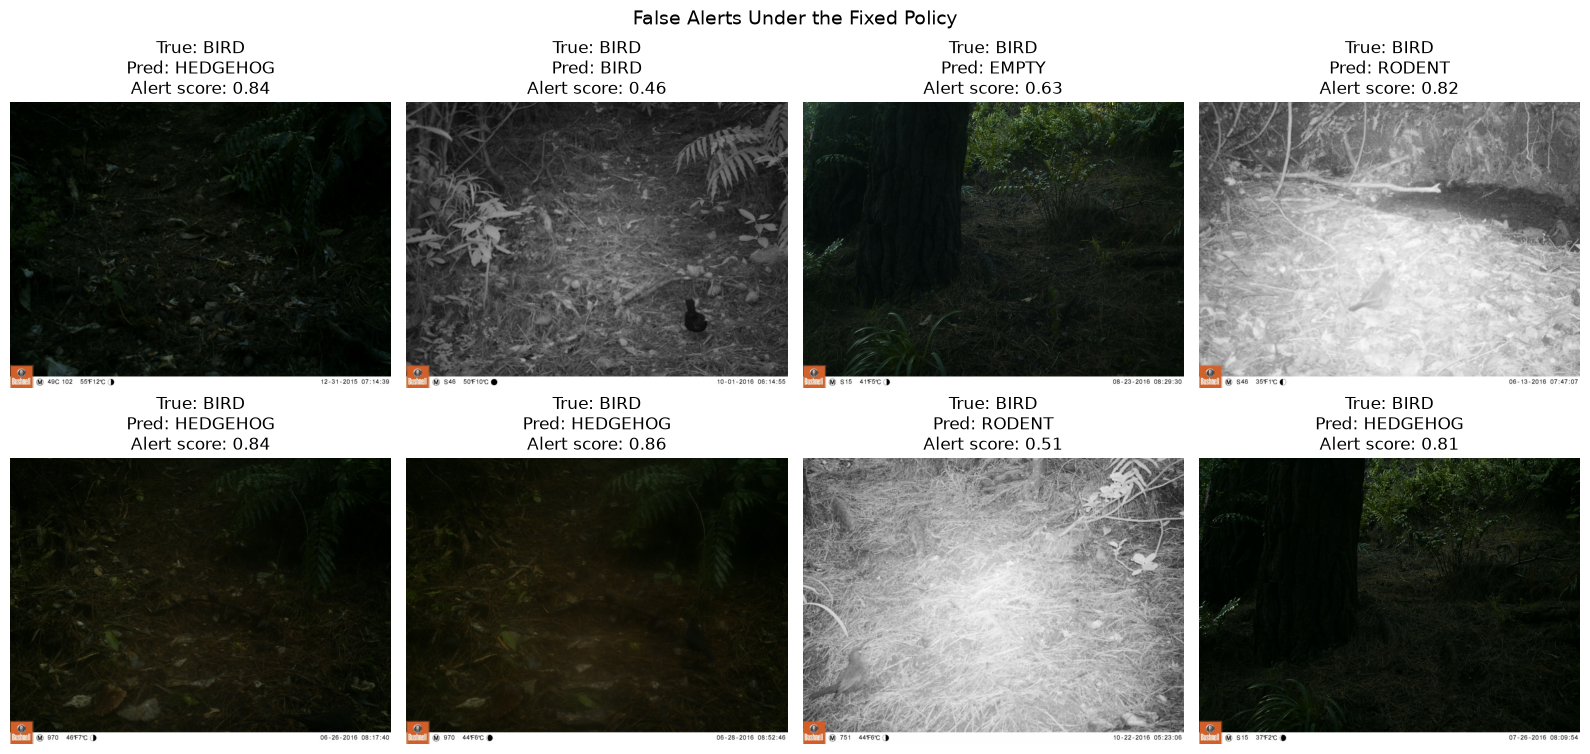

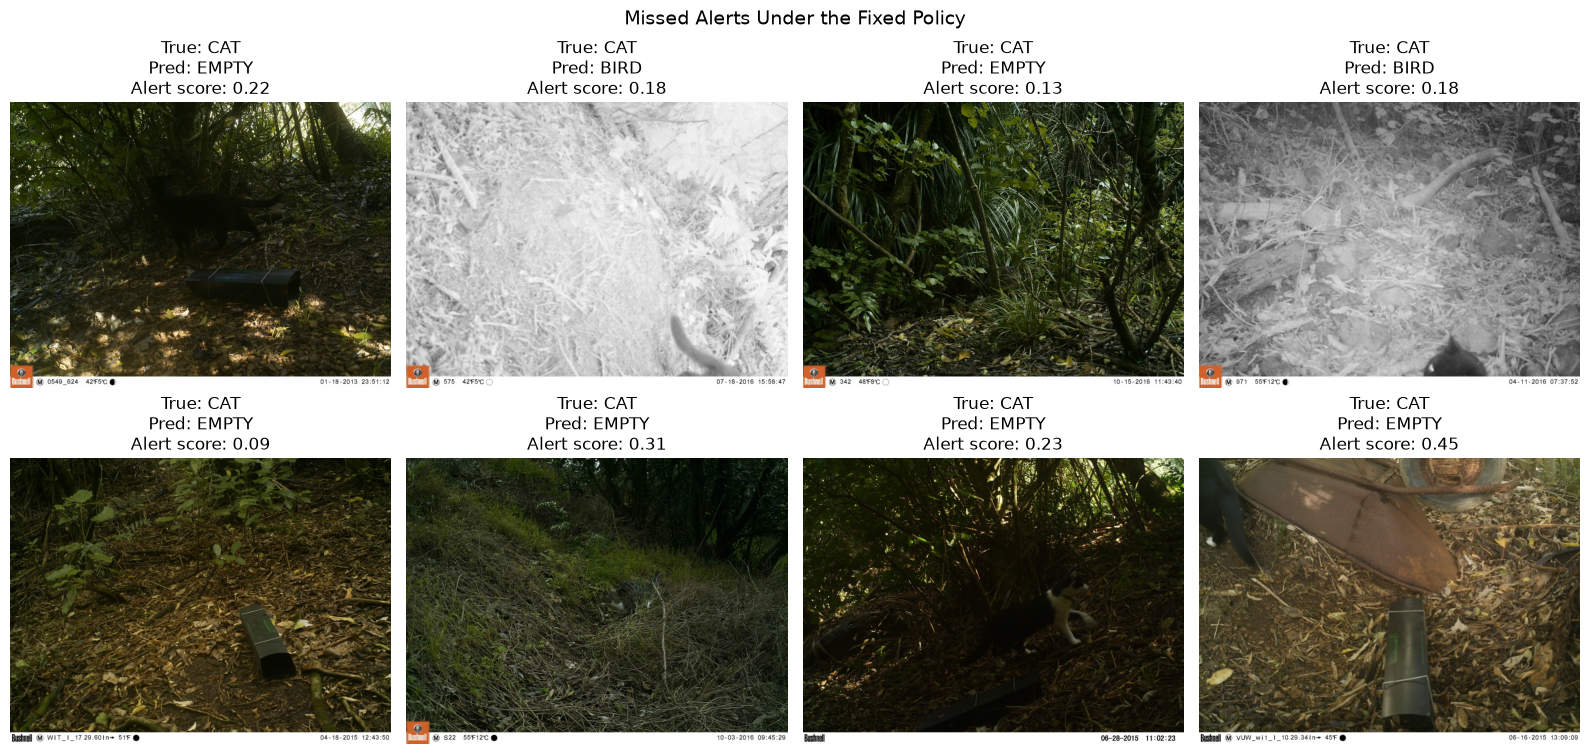

In [14]:
def show_alert_errors(predictions_df, mask, title, filename, n=8):
    examples = predictions_df.loc[mask].head(n)
    if examples.empty:
        print(f"No examples found for: {title}")
        return

    columns = 4
    rows = int(np.ceil(len(examples) / columns))
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 4 * rows),
        squeeze=False,
    )

    for axis in axes.ravel():
        axis.axis("off")

    for axis, (_, row) in zip(axes.ravel(), examples.iterrows()):
        image_path = (
            CACHE_DATA_DIR
            / row["split"]
            / row["project_class"]
            / row["file"]
        )
        with Image.open(image_path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(
            f"True: {row['true_class']}\n"
            f"Pred: {row['predicted_class']}\n"
            f"Alert score: {row['selected_alert_score']:.2f}"
        )
        axis.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / filename,
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()


false_alert_mask = (
    (test_predictions_df["true_alert"] == 0)
    & (test_predictions_df["predicted_alert"] == 1)
)
missed_alert_mask = (
    (test_predictions_df["true_alert"] == 1)
    & (test_predictions_df["predicted_alert"] == 0)
)

print("False alerts:", int(false_alert_mask.sum()))
print("Missed alerts:", int(missed_alert_mask.sum()))

show_alert_errors(
    test_predictions_df,
    false_alert_mask,
    "False Alerts Under the Fixed Policy",
    "final_false_alerts.png",
)
show_alert_errors(
    test_predictions_df,
    missed_alert_mask,
    "Missed Alerts Under the Fixed Policy",
    "final_missed_alerts.png",
)


## 7.2 Grad-CAM

In [16]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handle = target_layer.register_forward_hook(
            self._forward_hook
        )

    def _forward_hook(self, module, inputs, output):
        self.activations = output.detach()
        output.register_hook(self._gradient_hook)

    def _gradient_hook(self, gradient):
        self.gradients = gradient.detach()

    def generate(self, input_tensor, target_class):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        logits[0, target_class].backward()

        activations = self.activations[0]
        gradients = self.gradients[0]
        weights = gradients.mean(dim=(1, 2), keepdim=True)
        cam = torch.relu((weights * activations).sum(dim=0))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(
            cam[None, None],
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        return cam.cpu().numpy()

    def close(self):
        self.handle.remove()


IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])


def prepare_gradcam_input(row):
    image_path = (
        CACHE_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )
    with Image.open(image_path) as image:
        tensor = eval_transform(image.convert("RGB"))

    display_image = tensor.permute(1, 2, 0).numpy()
    display_image = display_image * IMAGENET_STD + IMAGENET_MEAN
    display_image = np.clip(display_image, 0, 1)
    return tensor.unsqueeze(0).to(device), display_image


## 7.3 Grad-CAM Alert Examples

Use fixed examples for reproducibility. The missed-alert example was chosen
from visibly confirmed animal images for qualitative explanation only; this
choice does not alter the test predictions, counts, or reported metrics.


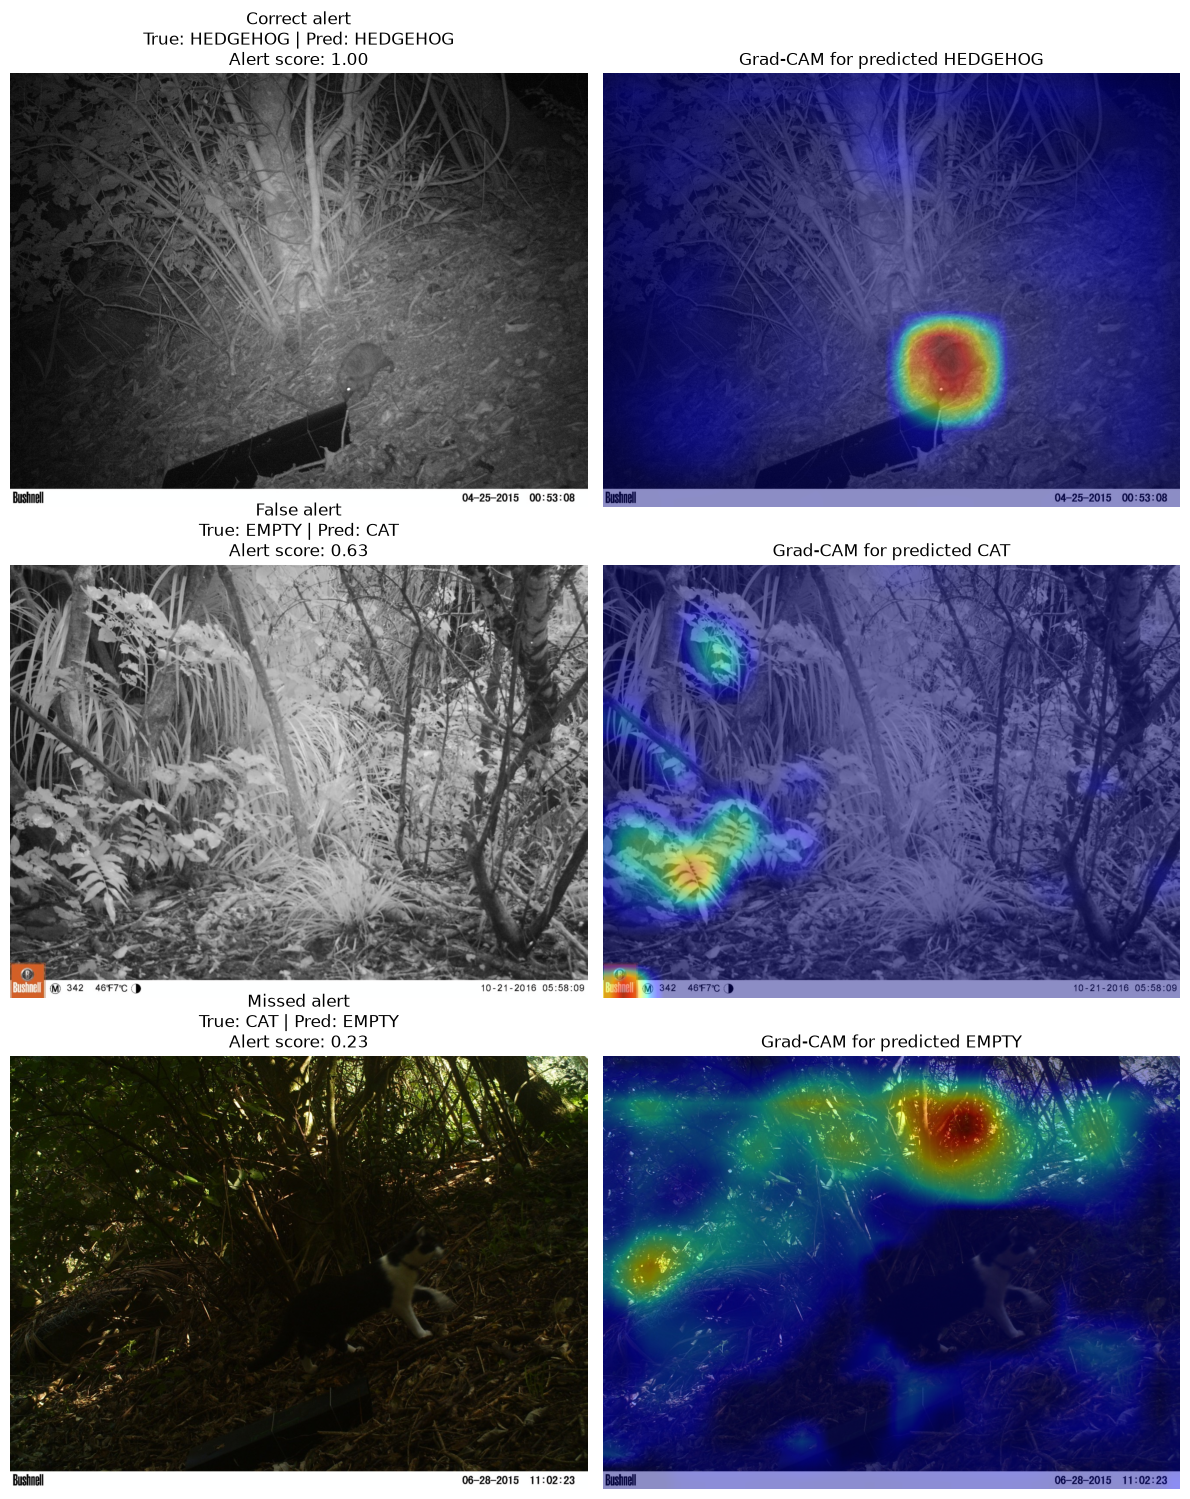

In [18]:
gradcam_cases = {
    "Correct alert": (
        (test_predictions_df["true_alert"] == 1)
        & (test_predictions_df["predicted_alert"] == 1)
    ),
    "False alert": false_alert_mask,
    "Missed alert": missed_alert_mask,
}

# Keep deterministic examples. For the missed-alert panel, use a
# manually verified image in which the cat is clearly visible. This is only
# qualitative case selection and does not change any evaluation metric.
preferred_example_files = {
    "Missed alert": "2806151102220549S262.jpg",
}

selected_gradcam_examples = []
for case_name, mask in gradcam_cases.items():
    candidates = test_predictions_df.loc[mask]
    if candidates.empty:
        continue

    preferred_file = preferred_example_files.get(case_name)
    if preferred_file is None:
        selected_row = candidates.sample(
            n=1,
            random_state=42,
        ).iloc[0]
    else:
        preferred_rows = candidates.loc[
            candidates["file"] == preferred_file
        ]
        if preferred_rows.empty:
            raise ValueError(
                f"Preferred {case_name} example was not found: "
                f"{preferred_file}"
            )
        selected_row = preferred_rows.iloc[0]

    selected_gradcam_examples.append((case_name, selected_row))

if not selected_gradcam_examples:
    raise ValueError("No Grad-CAM examples are available.")

gradcam = GradCAM(
    model=resnet_model,
    target_layer=resnet_model.layer4[-1],
)

fig, axes = plt.subplots(
    len(selected_gradcam_examples),
    2,
    figsize=(12, 5 * len(selected_gradcam_examples)),
    squeeze=False,
)

for row_number, (case_name, row) in enumerate(selected_gradcam_examples):
    input_tensor, display_image = prepare_gradcam_input(row)
    predicted_index = int(row["predicted_class_index"])
    heatmap = gradcam.generate(input_tensor, predicted_index)

    axes[row_number, 0].imshow(display_image)
    axes[row_number, 0].set_title(
        f"{case_name}\n"
        f"True: {row['true_class']} | Pred: {row['predicted_class']}\n"
        f"Alert score: {row['selected_alert_score']:.2f}"
    )
    axes[row_number, 0].axis("off")

    axes[row_number, 1].imshow(display_image)
    axes[row_number, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[row_number, 1].set_title(
        f"Grad-CAM for predicted {row['predicted_class']}"
    )
    axes[row_number, 1].axis("off")

gradcam.close()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "gradcam_alert_examples.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


### Grad-CAM Analysis

Grad-CAM was used to examine which image regions influenced the model’s predictions. The red and yellow areas show the regions that had the greatest influence on each prediction.

In the correct alert example, the strongest activation is centred on the hedgehog. This shows that the model used relevant features of the animal to make the correct prediction.

In the false alert example, an empty image was classified as CAT because the model focused mainly on leaves and vegetation. In the missed alert example, the cat is clearly visible, but its dark body blends into the background. The model focused on brighter vegetation instead and predicted EMPTY.

Overall, the model can identify animals correctly in clear cases, but it sometimes relies on background information rather than the animal itself. More difficult empty images, varied lighting conditions, and animal location labels could improve its reliability.

## 7.4 Data Quality Robustness Analysis

The following analysis uses the fixed final test predictions to describe where
errors occur. It is post-hoc error analysis only and is not used to change the
model, alert method, or validation-selected threshold.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

quality_rows = []
for quality_status, group in test_predictions_df.groupby(
    "quality_status",
    sort=True,
):
    y_true = group["true_alert"].to_numpy()
    y_pred = group["predicted_alert"].to_numpy()

    quality_rows.append(
        {
            "quality_status": quality_status,
            "images": len(group),
            "multiclass_accuracy": accuracy_score(
                group["true_class_index"],
                group["predicted_class_index"],
            ),
            "alert_accuracy": accuracy_score(y_true, y_pred),
            "alert_precision": precision_score(
                y_true,
                y_pred,
                zero_division=0,
            ),
            "alert_recall": recall_score(
                y_true,
                y_pred,
                zero_division=0,
            ),
            "alert_f1": f1_score(
                y_true,
                y_pred,
                zero_division=0,
            ),
            "false_alerts": int(
                ((group["true_alert"] == 0)
                 & (group["predicted_alert"] == 1)).sum()
            ),
            "missed_alerts": int(
                ((group["true_alert"] == 1)
                 & (group["predicted_alert"] == 0)).sum()
            ),
        }
    )

test_quality_metrics_df = pd.DataFrame(quality_rows)

true_alert_df = test_predictions_df.loc[
    test_predictions_df["true_alert"] == 1
].copy()

test_alert_recall_by_class_df = (
    true_alert_df.groupby("true_class", sort=True)
    .agg(
        total_images=("file", "size"),
        detected_alerts=("predicted_alert", "sum"),
    )
    .reset_index()
)
test_alert_recall_by_class_df["missed_alerts"] = (
    test_alert_recall_by_class_df["total_images"]
    - test_alert_recall_by_class_df["detected_alerts"]
)
test_alert_recall_by_class_df["alert_recall"] = (
    test_alert_recall_by_class_df["detected_alerts"]
    / test_alert_recall_by_class_df["total_images"]
)

test_quality_metrics_df.to_csv(
    RESULTS_DIR / "test_metrics_by_quality.csv",
    index=False,
)
test_alert_recall_by_class_df.to_csv(
    RESULTS_DIR / "test_alert_recall_by_class.csv",
    index=False,
)

print("Final test performance by image-quality group")
display(test_quality_metrics_df.round(4))

print("Alert recall by true predator class")
display(test_alert_recall_by_class_df.round(4))


### Quality Analysis Summary

The manually defined `review` group contains only 110 test images, but its
performance is clearly lower than the `keep` group. This confirms that poor
lighting and low image quality make the task more difficult. However, visual
inspection also found possible sequence-label noise that cannot be detected by
brightness and contrast rules alone. CAT is the weakest alert class, accounting
for most missed alerts. These findings are reported as limitations and are not
used to retune the final policy.
